# Resultado Analítico

## Imports

In [2]:
import Plots
using LinearAlgebra
import DifferentialEquations as DE
import ControlSystems as CS

## Matrices problema linealizado

In [3]:
A = [
	0 1;
	0 0;
]

B = [
	0,
	-1
] 

2-element Vector{Int64}:
  0
 -1

## Funciones de dinámicas

In [4]:
function control_clasico!(dx, x, p, t)
	Ap, Bp, u = p
	dx .= Ap*x + Bp*u(t)
end

control_clasico! (generic function with 1 method)

In [23]:
function control_feedback!(dx, x, p, t)
	Ap, Bp, Kp = p
	dx .= (Ap+Bp*Kp)*x
end

control_feedback! (generic function with 1 method)

In [24]:
function control_paper!(dx, x, p, t)
	Ap, Bp, T_hit = p
	t_go = T_hit - t
	u = 3*(x[1]+x[2]*t_go)/(t_go^2)
	dx .= Ap*x + Bp*u
end

control_paper! (generic function with 1 method)

In [26]:
function control_paper_qf!(dx, x, p, t)
	Ap, Bp, q_f, T_hit = p
	t_go = T_hit - t
	u = 3*(x[1]+x[2]*t_go)/(t_go^2+3/(q_f*t_go))
	dx .= Ap*x + Bp*u
end

control_paper_qf! (generic function with 1 method)

In [25]:
# function riccati!(dE, E, p, t)
# 	Ar, Br, Wr, Ur = p
# 	A, B, W, U = reshape(Ar, 2,2), reshape(Br, 2,2), reshape(Wr, 2,2), reshape(Ur, 2,2) 
# 	Er = reshape(E, 2,2)
# 	dE .= vec(W - A'*Er - Er'*A - Er'*B*B'*Er/U) # <- como u es de dim 1 U es escalar
# end

function riccati!(dE, E, p, t)
	A, B, W, U = p
    Er  = reshape(E, 2, 2)
    dEr = -A' * Er - Er * A - Er * B * (B' * Er) / U + W
    dE .= vec(dEr)
end

riccati! (generic function with 1 method)

## Controles

In [20]:
u1(t) = sin(t)*5

u1 (generic function with 1 method)

## Valores de prueba

In [59]:
ry0 = -10 # <- al ser la orientación del problema arbitrario podemos fijarla a LOS en t0 para facilitar las condiciones iniciales
vy0 = 20 # [m/s]?
rx0 = 1200 # distancia horizontal
vx0 = -30

T_choque = -rx0/vx0

z0 = [ry0, vy0]

tspan = (0.0, T_choque)

(0.0, 40.0)

## Gráficos

### Chequeo funcionamiento

In [30]:
prob_chk = CS.ODEProblem(control_clasico!, z0, tspan, (A, B, u1))
din_chk = CS.solve(prob_chk)

retcode: Success
Interpolation: 3rd order Hermite
t: 26-element Vector{Float64}:
  0.0
  0.09330516514502563
  0.441864146891798
  0.9478093234541871
  1.5607527692487897
  2.460145568107734
  3.4246497270657974
  4.570093535239818
  5.844181991692104
  7.316422156695829
  ⋮
 22.3493894921396
 24.524276623035348
 26.574109846337727
 28.80525278589857
 31.195461302911227
 33.3003031875693
 35.52082698660726
 38.05224394080514
 40.0
u: 26-element Vector{Vector{Float64}}:
 [-10.0, 20.0]
 [-8.134573320110547, 19.978251150795067]
 [-1.2339112197974524, 19.519780406716023]
 [8.277836057937874, 17.91731828741492]
 [18.41103748897625, 15.050217489920888]
 [30.051739081910963, 11.116691515125572]
 [39.97321041992223, 10.198964513950889]
 [53.60185482255779, 14.290888525927913]
 [75.53770300979154, 19.525832141164493]
 [104.04176171042405, 17.560285985290776]
 ⋮
 [323.4786193517213, 10.317164852206673]
 [354.9993959619873, 19.100696007970495]
 [393.5642047587475, 15.64452540894861]
 [419.5267188

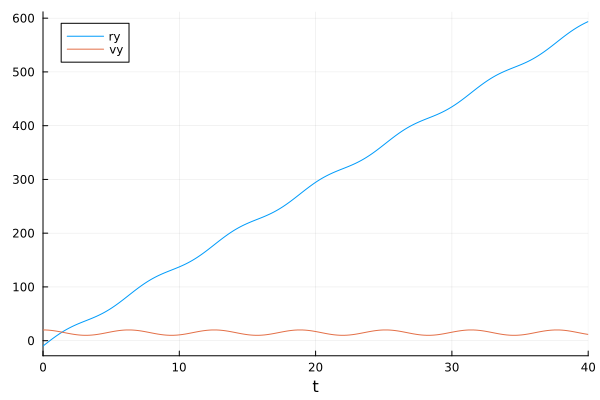

In [31]:
Plots.plot(din_chk, labels=["ry" "vy"])

### Restricción dura

In [32]:
prob_paper = CS.ODEProblem(control_paper!, z0, tspan, (A, B, T_choque))
din_paper = CS.solve(prob_paper)

retcode: Success
Interpolation: 3rd order Hermite
t: 71-element Vector{Float64}:
  0.0
  0.09329237844550865
  1.445212166654613
  4.630401775574302
  9.277458842000549
 14.422145585800095
 19.916810354819347
 24.763132087129875
 30.264602438401955
 34.93454769276651
  ⋮
 39.99999999998983
 39.999999999991864
 39.999999999993896
 39.99999999999593
 39.99999999999766
 39.99999999999841
 39.99999999999886
 39.99999999999922
 40.0
u: 71-element Vector{Vector{Float64}}:
 [-10.0, 20.0]
 [-8.140593425625326, 19.861971814574982]
 [17.375975627529005, 17.897951919488378]
 [67.34131343547303, 13.538203676430458]
 [116.73108361327392, 7.851422437080359]
 [142.9086311280856, 2.4883918390989654]
 [143.3076419427328, -2.1571192428151256]
 [124.82320284932938, -5.326582230638206]
 [88.01588729562621, -7.872812893949002]
 [47.97638363722171, -9.166437891640722]
 ⋮
 [9.781700899269666e-11, -9.62569272795306]
 [7.824348713944977e-11, -9.633312143013663]
 [5.866119811782869e-11, -9.6409297776815]
 [3.90

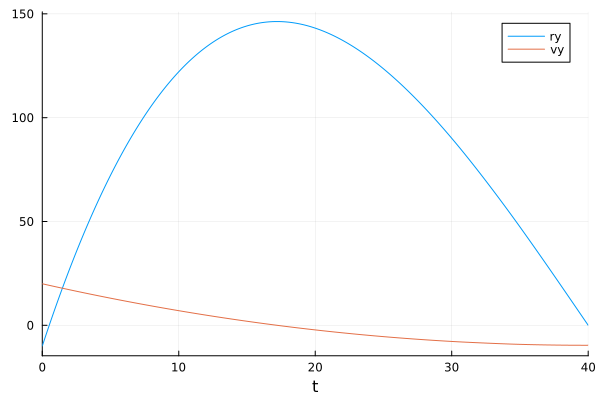

In [33]:
Plots.plot(din_paper, labels=["ry" "vy"])

### Restricciones blandas

In [35]:
prob_margen = CS.ODEProblem(control_paper_qf!, z0, tspan, (A, B, 1, T_choque))
din_margen = CS.solve(prob_margen)

retcode: Success
Interpolation: 3rd order Hermite
t: 12-element Vector{Float64}:
  0.0
  0.09329237964327443
  1.4454226423081384
  4.630892915196447
  9.278189180558817
 14.423209486031471
 19.918267802207946
 24.765190693509055
 30.268198672562068
 34.94361729873193
 38.17533561898221
 40.0
u: 12-element Vector{Vector{Float64}}:
 [-10.0, 20.0]
 [-8.14059309992786, 19.861978282572935]
 [17.379814333966564, 17.89774996045587]
 [67.34867816941923, 13.537863308436716]
 [116.73957489774412, 7.851161022450515]
 [142.917631760804, 2.4882050285145616]
 [143.3159838446333, -2.1571643753511123]
 [124.82913306280885, -5.326555992643258]
 [88.01131438552547, -7.872767601687734]
 [47.922317845345205, -9.165301831905921]
 [17.578795456776987, -9.572698336186251]
 [0.03628642060402343, -9.63580799606682]

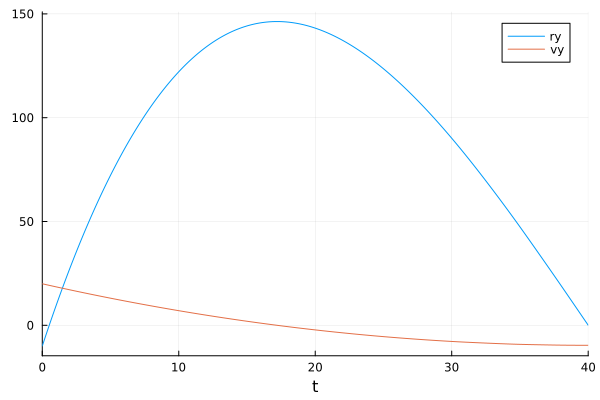

In [36]:
Plots.plot(din_margen, labels=["ry" "vy"])

### Gráficos trayectorias y choques

In [60]:
p0 = [rx0, ry0] # centramos los ejes en la posición inicial del misil
B_O = [vx0/2;vy0] # para hacer mas interesante la simulación el aporte de cada objeto en movimiento a la velocidad relativa en x será repartido 
u_O(t) = 1

u_O (generic function with 1 method)

In [61]:
prob_obj = CS.ODEProblem(control_clasico!, p0, tspan, (zeros(2,2), B_O, u_O))
din_obj = CS.solve(prob_obj)

retcode: Success
Interpolation: 3rd order Hermite
t: 4-element Vector{Float64}:
  0.0
  0.7071280290390067
 29.207792269486937
 40.0
u: 4-element Vector{Vector{Float64}}:
 [1200.0, -10.0]
 [1189.3930795644148, 4.142560580780132]
 [761.8831159576961, 574.1558453897387]
 [600.0000000000002, 789.9999999999999]

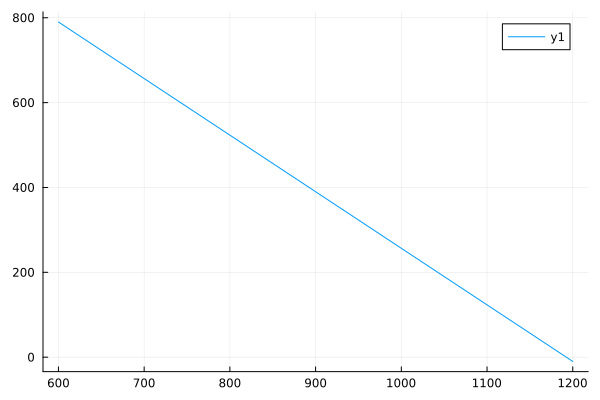

In [76]:
f_x(t) = din_obj(t)[1]
f_y(t) = din_obj(t)[2]

Plots.plot(f_x, f_y, 0, 40, idxs=(1,2))

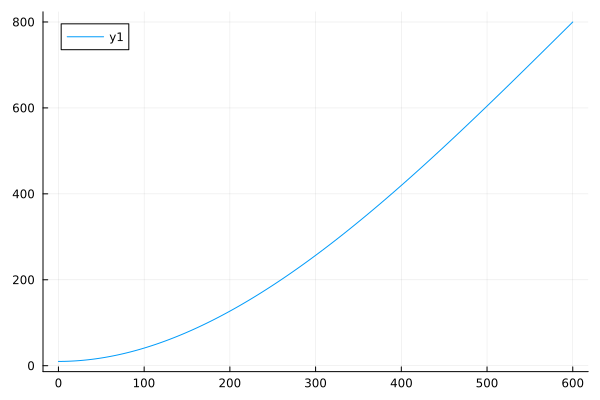

In [73]:
g_x(t) = (-vx0/2)*t
g_y(t) = vy0*t-din_paper(t)[1]
Plots.plot(g_x, g_y, 0, 40, idxs=(1,2))


In [80]:
f_y(40)

789.9999999999989